## Interval Analysis

In [ ]:
# !pip install tensorboardX

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import numpy as np
import time
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
# from tensorboardX import SummaryWriter

use_cuda = False
device = torch.device("cuda" if use_cuda else "cpu")
batch_size = 64

np.random.seed(42)
torch.manual_seed(42)


## Dataloaders
train_dataset = datasets.MNIST('mnist_data/', train=True, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))
test_dataset = datasets.MNIST('mnist_data/', train=False, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

## Simple NN. You can change this if you want. If you change it, mention the architectural details in your report.
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.fc = nn.Linear(28*28, 200)
        self.fc2 = nn.Linear(200,10)

    def forward(self, x):
        x = x.view((-1, 28*28))
        x = F.relu(self.fc(x))
        x = self.fc2(x)
        x = F.softmax(x, dim=-1) # added softmax for probabilities
        return x

class Normalize(nn.Module):
    def forward(self, x):
        return (x - 0.1307)/0.3081

# Add the data normalization as a first "layer" to the network
# this allows us to search for adverserial examples to the real image, rather than
# to the normalized image
model = nn.Sequential(Normalize(), Net())

model = model.to(device)
model.train()


Sequential(
  (0): Normalize()
  (1): Net(
    (fc): Linear(in_features=784, out_features=200, bias=True)
    (fc2): Linear(in_features=200, out_features=10, bias=True)
  )
)

In [ ]:
def train_model(model, num_epochs):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=0.001, momentum=0.9)

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        for i, data in enumerate(train_loader, 0):
            images, labels = data
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        print(f'Epoch {epoch+1}/{num_epochs}, Loss: {running_loss/len(train_loader):.3f}')

def test_model(model):
    model.eval()
    with torch.no_grad():
        correct = 0
        total = 0
        for data in test_loader:
            images, labels = data
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
        print(f'Accuracy on images: {100 * correct / total}')

In [ ]:
# train your network on MNIST with 15 epochs and report the clean accuracy.
train_model(model, 15)
test_model(model)

Epoch 1/15, Loss: 2.012
Epoch 2/15, Loss: 1.729
Epoch 3/15, Loss: 1.627
Epoch 4/15, Loss: 1.596
Epoch 5/15, Loss: 1.582
Epoch 6/15, Loss: 1.572
Epoch 7/15, Loss: 1.566
Epoch 8/15, Loss: 1.561
Epoch 9/15, Loss: 1.557
Epoch 10/15, Loss: 1.553
Epoch 11/15, Loss: 1.550
Epoch 12/15, Loss: 1.547
Epoch 13/15, Loss: 1.545
Epoch 14/15, Loss: 1.542
Epoch 15/15, Loss: 1.540
Accuracy on images: 93.43


### Write the interval analysis for the simple model

In [ ]:
def ibp(layer, lower, upper):
    if isinstance(layer, nn.Linear):
        center, rad = (upper + lower) / 2, (upper - lower) / 2
        center = layer(center)                    # W·center + b
        rad = rad @ layer.weight.abs().T          # |W|·rad
        return center - rad, center + rad
    if isinstance(layer, Normalize):
        return layer(lower), layer(upper)         # monotone, so apply to both bounds
    raise NotImplementedError(type(layer))

In [ ]:
def diff_lower_bound(model, x, y, eps):
    # Lower bound of f_y - f_j for every j != y. Returns (B, 10)
    norm, net = model[0], model[1]

    # input box, clipped to the valid image range [0, 1]
    lower, upper = (x - eps).clamp(0, 1), (x + eps).clamp(0, 1)

    lower, upper = ibp(norm, lower, upper)
    lower, upper = lower.flatten(1), upper.flatten(1)
    lower, upper = ibp(net.fc, lower, upper)

    # Monotone, so apply to both bounds
    lower, upper = F.relu(lower), F.relu(upper)

    # extra output layer: row j is W_y - W_j, bias b_y - b_j
    W, b = net.fc2.weight, net.fc2.bias
    W_diff = W[y].unsqueeze(1) - W.unsqueeze(0)      # (B, 10, 200)
    b_diff = b[y].unsqueeze(1) - b                   # (B, 10)

    center, rad = (upper + lower) / 2, (upper - lower) / 2
    low = (W_diff * center.unsqueeze(1) - W_diff.abs() * rad.unsqueeze(1)).sum(dim=2) + b_diff

    return low.scatter(1, y.unsqueeze(1), float('inf'))  # ignore j == y

In [ ]:
@torch.no_grad()
def verify(model, eps, verbose=True):
    model.eval()
    margin_sum, verified = 0.0, 0
    for X, y in test_loader:
        X, y = X.to(device), y.to(device)
        margin = diff_lower_bound(model, X, y, eps).min(dim=1).values  # worst-case f_y - f_j
        margin_sum += margin.sum().item()
        # Interval analysis proves the property if the lower bound of each of these
        # outputs is not negative.
        verified += (margin >= 0).sum().item()

    n = len(test_dataset)
    if verbose:
        print(f'eps={eps:.2f} | verified: {verified / n:.2%} | avg worst-case logit margin: {margin_sum / n:.3f}')
    return verified / n

In [ ]:
# eps = 0 should reproduce clean accuracy
print('eps=0 verified accuracy:', f'{verify(model, 0.0, verbose=False):.2%}', '(clean accuracy was 93.43%)')

eps=0 verified accuracy: 93.43% (clean accuracy was 93.43%)


eps=0.01 | verified: 70.55% | avg worst-case logit margin: 1.977
eps=0.02 | verified: 23.68% | avg worst-case logit margin: -3.154
eps=0.03 | verified: 4.56% | avg worst-case logit margin: -8.277
eps=0.04 | verified: 0.58% | avg worst-case logit margin: -13.355
eps=0.05 | verified: 0.02% | avg worst-case logit margin: -18.354
eps=0.06 | verified: 0.00% | avg worst-case logit margin: -23.252
eps=0.07 | verified: 0.00% | avg worst-case logit margin: -28.018
eps=0.08 | verified: 0.00% | avg worst-case logit margin: -32.621
eps=0.09 | verified: 0.00% | avg worst-case logit margin: -37.033
eps=0.10 | verified: 0.00% | avg worst-case logit margin: -41.255

| eps | verified accuracy |
|---|---|
| 0.01 | 70.55% |
| 0.02 | 23.68% |
| 0.03 | 4.56% |
| 0.04 | 0.58% |
| 0.05 | 0.02% |
| 0.06 | 0.00% |
| 0.07 | 0.00% |
| 0.08 | 0.00% |
| 0.09 | 0.00% |
| 0.10 | 0.00% |


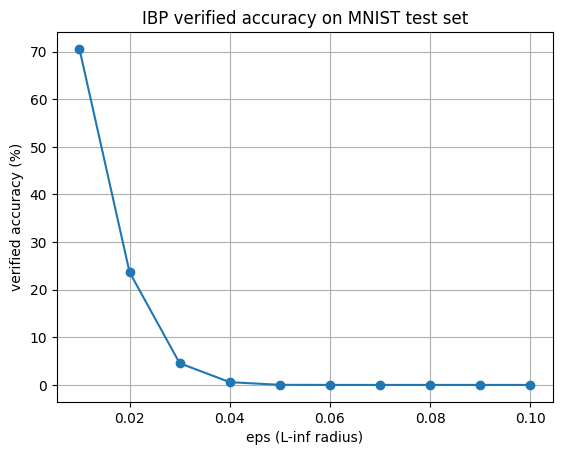

In [ ]:
eps_list = np.linspace(0.01, 0.1, 10)
results = [verify(model, e) for e in eps_list]

print('\n| eps | verified accuracy |\n|---|---|')
for e, r in zip(eps_list, results):
    print(f'| {e:.2f} | {r*100:.2f}% |')

plt.plot(eps_list, [100 * r for r in results], marker='o')
plt.xlabel('eps (L-inf radius)'); plt.ylabel('verified accuracy (%)')
plt.title('IBP verified accuracy on MNIST test set'); plt.grid(True); plt.show()